
# Projeto Integrador – BDED 2026.1

## Previsão de Atrasos em Entregas do Comércio Eletrônico utilizando Machine Learning

**Especialização em Projetos de Inteligência Artificial**  
**Disciplina:** Banco de Dados e Engenharia de Dados  
**Aluno:** Rodrigo Nobre  
**Ano:** 2026

---

### 1. Introdução

O comércio eletrônico movimenta diariamente milhares de pedidos, e um dos principais desafios das empresas é garantir que os produtos sejam entregues dentro do prazo informado ao cliente.

Neste projeto, são utilizadas técnicas de Engenharia de Dados e Machine Learning para analisar pedidos de uma plataforma brasileira de comércio eletrônico e desenvolver modelos capazes de identificar possíveis atrasos nas entregas.

### 2. Objetivo

Desenvolver um pipeline de dados que integre diferentes fontes de informação, realize o tratamento e a organização dos registros em um banco PostgreSQL e utilize algoritmos de classificação para prever atrasos nas entregas.

### 3. Fontes de dados

Foram utilizadas duas fontes independentes:

**Fonte 1 – Brazilian E-Commerce Public Dataset by Olist**

Base pública disponibilizada no Kaggle, contendo informações sobre pedidos, clientes, produtos, vendedores, pagamentos, avaliações e entregas realizadas no Brasil.

**Fonte 2 – Calendário de feriados brasileiros**

Calendário de feriados nacionais dos anos de 2016 a 2018, gerado com a biblioteca Python `holidays`, para identificar compras realizadas em feriados ou em datas próximas.

### 4. Tecnologias utilizadas

- Python e Pandas para processamento dos dados.
- PostgreSQL para armazenamento e integração das fontes.
- SQL para construção da base analítica.
- Scikit-learn para treinamento e avaliação dos modelos.
- Matplotlib para visualização dos resultados.
- Jupyter Notebook para documentação dos experimentos.

### 5. Metodologia

O desenvolvimento foi organizado nas seguintes etapas:

1. Coleta dos dados de duas fontes independentes.
2. Criação do banco de dados PostgreSQL.
3. Desenvolvimento do processo ETL.
4. Integração e construção das características dos pedidos.
5. Separação cronológica dos dados de treinamento e teste.
6. Treinamento dos modelos Regressão Logística e Random Forest.
7. Avaliação por Accuracy, Precision, Recall, F1-score e matriz de confusão.
8. Análise dos resultados e conclusões.


In [1]:
import pandas as pd
import psycopg

# Conexão com o banco PostgreSQL
conn = psycopg.connect(dbname="projeto_integrador_bded")

# Consulta à base analítica
with conn.cursor() as cursor:
    cursor.execute("""
        SELECT *
        FROM analytics.delivery_features
        ORDER BY data_compra, order_id
    """)

    colunas = [col.name for col in cursor.description]
    dados = cursor.fetchall()

df = pd.DataFrame(dados, columns=colunas)
conn.close()

print(f"Total de pedidos: {len(df):,}")
print(f"Total de características: {df.shape[1]}")

display(df.head())

Total de pedidos: 96,470
Total de características: 24


,order_id,ano_compra,mes_compra,dia_semana_compra,hora_compra,compra_fim_semana,estado_cliente,quantidade_itens,produtos_distintos,vendedores_distintos,...,vendedor_outro_estado,valor_pagamento,parcelas_maximas,quantidade_pagamentos,pagamento_cartao,compra_em_feriado,compra_proxima_feriado,prazo_estimado_dias,data_compra,atrasou
0,bfbd0f9bdef84302105ad712db648a6c,2016,9,4,12,0,SP,3,1,1,...,1,0,0,0,0,0,0,19,2016-09-15 12:16:38,1
1,3b697a20d9e427646d92567910af6d57,2016,10,1,9,0,SP,1,1,1,...,1,45.46,1,1,0,0,0,24,2016-10-03 09:44:50,0
2,be5bc2f0da14d8071e2d45451ad119d9,2016,10,1,16,0,RS,1,1,1,...,1,39.09,1,1,0,0,0,35,2016-10-03 16:56:50,0
3,a41c8759fbe7aab36ea07e038b2d4465,2016,10,1,21,0,RS,1,1,1,...,1,53.73,1,1,0,0,0,57,2016-10-03 21:13:36,0
4,d207cc272675637bfed0062edffd0818,2016,10,1,22,0,SP,1,1,1,...,0,133.46,6,1,1,0,0,51,2016-10-03 22:06:03,0


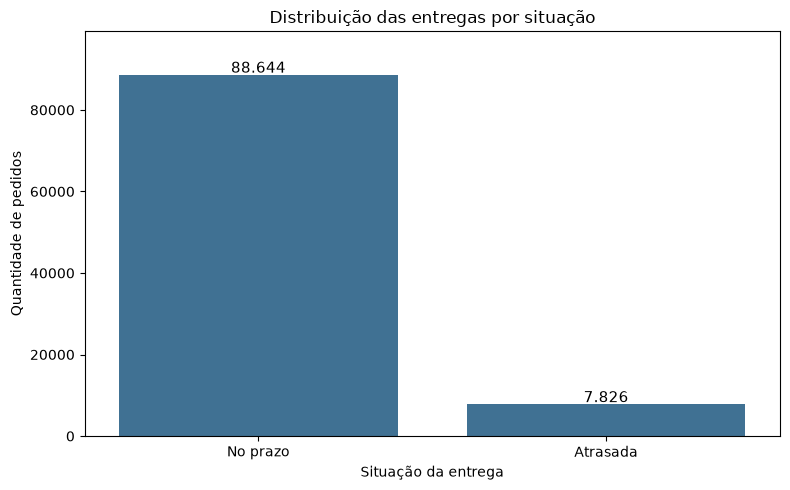

Entregas no prazo: 88,644
Entregas atrasadas: 7,826
Percentual de atrasos: 8.11%


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Contagem de entregas por situação
contagem = df["atrasou"].value_counts().reindex([0, 1], fill_value=0)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["No prazo", "Atrasada"],
    y=contagem.values,
    color="#3274A1"
)

for i, valor in enumerate(contagem.values):
    ax.text(
        i, valor + 500,
        f"{valor:,}".replace(",", "."),
        ha="center",
        fontsize=11
    )

plt.title("Distribuição das entregas por situação")
plt.xlabel("Situação da entrega")
plt.ylabel("Quantidade de pedidos")
plt.ylim(0, contagem.max() * 1.12)
plt.tight_layout()
plt.show()

print(f"Entregas no prazo: {contagem[0]:,}")
print(f"Entregas atrasadas: {contagem[1]:,}")
print(f"Percentual de atrasos: {df['atrasou'].mean() * 100:.2f}%")

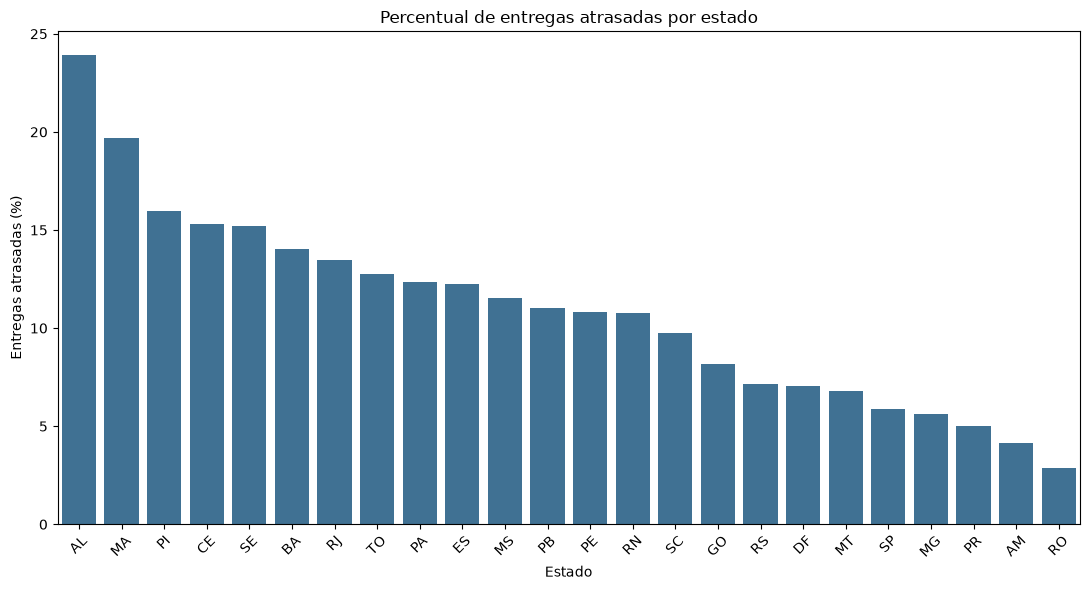

,estado_cliente,total_pedidos,pedidos_atrasados,percentual_atrasos
1,AL,397,95,23.93
9,MA,717,141,19.67
16,PI,476,76,15.97
5,CE,1279,196,15.32
24,SE,335,51,15.22
4,BA,3256,457,14.04
18,RJ,12350,1664,13.47
26,TO,274,35,12.77
13,PA,946,117,12.37
7,ES,1995,244,12.23


In [3]:
# Análise das entregas por estado
atrasos_estado = (
    df.groupby("estado_cliente")
    .agg(
        total_pedidos=("atrasou", "count"),
        pedidos_atrasados=("atrasou", "sum"),
        percentual_atrasos=("atrasou", "mean")
    )
    .reset_index()
)

atrasos_estado["percentual_atrasos"] *= 100

# Considerar estados com pelo menos 100 pedidos
atrasos_estado = atrasos_estado[
    atrasos_estado["total_pedidos"] >= 100
]

atrasos_estado = atrasos_estado.sort_values(
    "percentual_atrasos", ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=atrasos_estado,
    x="estado_cliente",
    y="percentual_atrasos",
    color="#3274A1"
)

plt.title("Percentual de entregas atrasadas por estado")
plt.xlabel("Estado")
plt.ylabel("Entregas atrasadas (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(atrasos_estado.head(10).round(2))

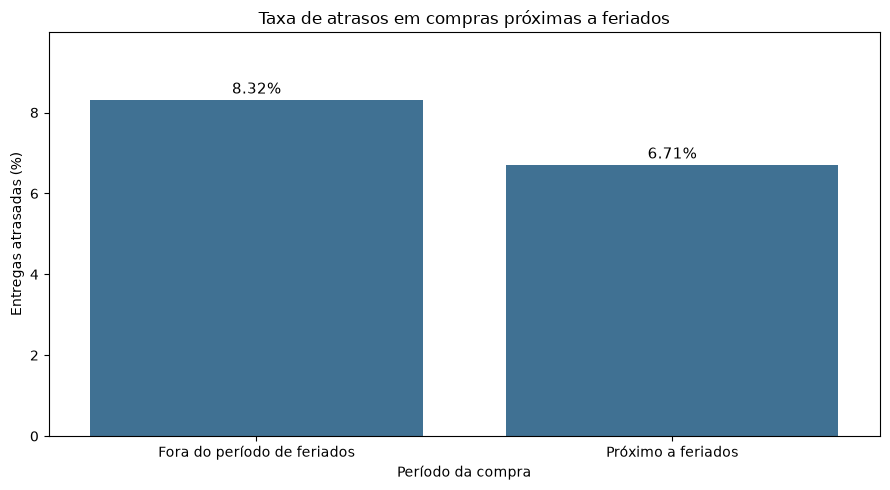

,situacao,total_pedidos,pedidos_atrasados,percentual_atrasos
0,Fora do período de feriados,84048,6992,8.32
1,Próximo a feriados,12422,834,6.71


In [4]:
# Análise da influência dos feriados nas entregas

analise_feriados = (
    df.groupby("compra_proxima_feriado")
    .agg(
        total_pedidos=("atrasou", "count"),
        pedidos_atrasados=("atrasou", "sum"),
        percentual_atrasos=("atrasou", "mean")
    )
    .reset_index()
)

analise_feriados["percentual_atrasos"] *= 100

analise_feriados["situacao"] = analise_feriados[
    "compra_proxima_feriado"
].map({
    0: "Fora do período de feriados",
    1: "Próximo a feriados"
})

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=analise_feriados,
    x="situacao",
    y="percentual_atrasos",
    color="#3274A1"
)

for i, valor in enumerate(analise_feriados["percentual_atrasos"]):
    ax.text(
        i, valor + 0.15,
        f"{valor:.2f}%",
        ha="center",
        fontsize=11
    )

plt.title("Taxa de atrasos em compras próximas a feriados")
plt.xlabel("Período da compra")
plt.ylabel("Entregas atrasadas (%)")
plt.ylim(0, max(analise_feriados["percentual_atrasos"]) * 1.2)
plt.tight_layout()
plt.show()

display(
    analise_feriados[
        ["situacao", "total_pedidos",
         "pedidos_atrasados", "percentual_atrasos"]
    ].round(2)
)


### 6. Análise exploratória dos dados

A base analítica utilizada no projeto contém 96.470 pedidos entregues, sendo 88.644 realizados dentro do prazo e 7.826 com atraso, representando uma taxa de atraso de 8,11%.

A análise revelou um desequilíbrio entre as classes, já que a maior parte dos pedidos foi entregue dentro do prazo. Essa característica exige atenção na avaliação dos modelos, principalmente em relação às métricas Precision, Recall e F1-score.

**Análise por estado:** foram identificadas diferenças regionais nas taxas de atraso. Alagoas apresentou 23,93%, Maranhão 19,67% e Piauí 15,97%, indicando que a localização geográfica pode contribuir para a identificação de padrões nas entregas.

**Análise dos feriados:** a integração com o calendário brasileiro mostrou que os pedidos realizados próximos a feriados nacionais apresentaram taxa de atraso de 6,71%, enquanto os demais registraram 8,32%.

Embora a diferença observada seja de 1,61 ponto percentual, não é possível afirmar que os feriados sejam responsáveis pela redução dos atrasos, pois outros fatores também podem influenciar o resultado.

Essas análises demonstram a importância da integração de diferentes fontes de dados e ajudam a compreender os desafios da construção de modelos preditivos para problemas reais.


,modelo,accuracy,precision,recall,f1_score
0,Regressao Logistica,0.5714,0.0809,0.6856,0.1448
1,Random Forest,0.6008,0.0425,0.3036,0.0745


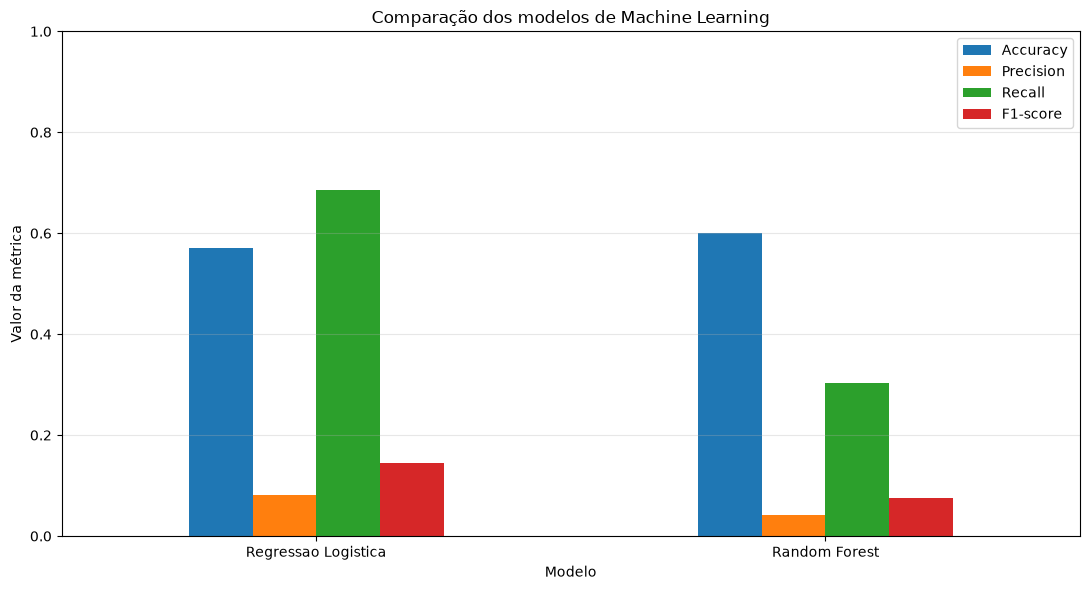

Melhor modelo: Regressao Logistica
F1-score: 0.1448
Recall: 0.6856


In [5]:
from pathlib import Path

# Localizar os resultados gerados pelo treinamento
arquivo_metricas = Path("../results/metricas_modelos.csv")

metricas = pd.read_csv(arquivo_metricas)

# Exibir tabela comparativa
display(metricas.round(4))

# Comparar as métricas dos modelos
metricas_grafico = metricas.set_index("modelo")[
    ["accuracy", "precision", "recall", "f1_score"]
]

ax = metricas_grafico.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Comparação dos modelos de Machine Learning")
plt.xlabel("Modelo")
plt.ylabel("Valor da métrica")
plt.ylim(0, 1)
plt.legend(["Accuracy", "Precision", "Recall", "F1-score"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Identificar o melhor modelo pelo F1-score
melhor = metricas.loc[metricas["f1_score"].idxmax()]

print(f"Melhor modelo: {melhor['modelo']}")
print(f"F1-score: {melhor['f1_score']:.4f}")
print(f"Recall: {melhor['recall']:.4f}")

Matriz de confusão — Regressão Logística


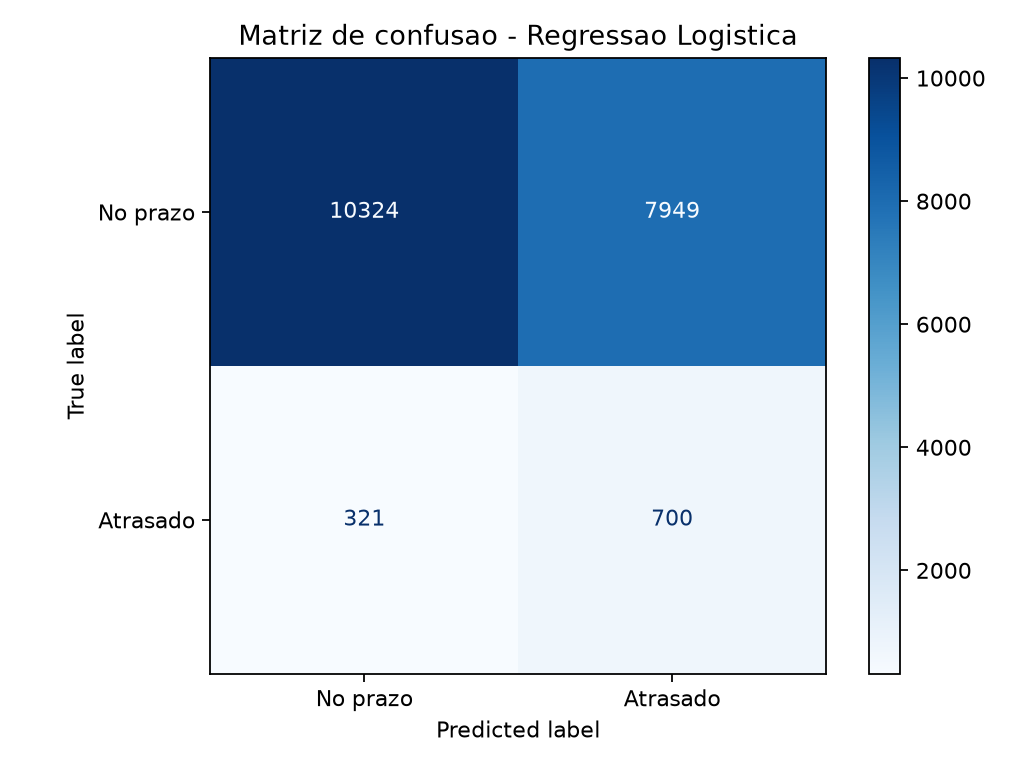

Matriz de confusão — Random Forest


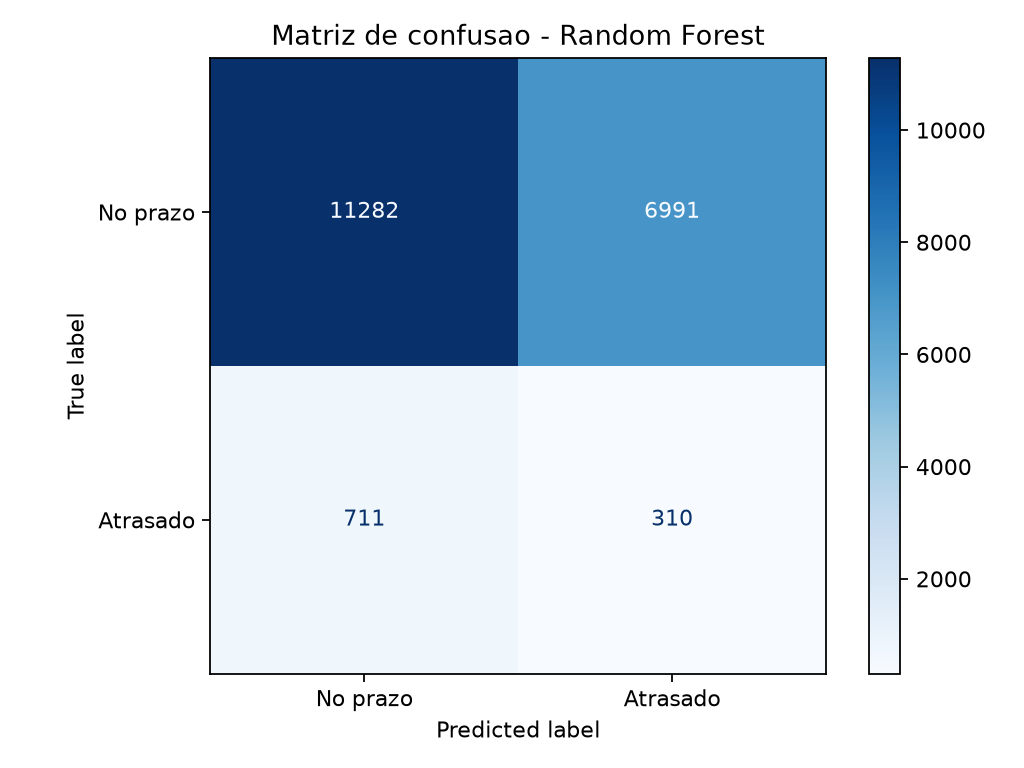

In [6]:
from IPython.display import Image, display

print("Matriz de confusão — Regressão Logística")
display(Image(filename="../results/matriz_regressao_logistica.png"))

print("Matriz de confusão — Random Forest")
display(Image(filename="../results/matriz_random_forest.png"))


### 7. Resultados e avaliação dos modelos

Foram treinados dois algoritmos de classificação: Regressão Logística e Random Forest. A divisão dos dados foi realizada de forma cronológica, utilizando 80% dos pedidos mais antigos para treinamento e 20% dos mais recentes para teste.

O conjunto de treinamento possui 77.176 pedidos, enquanto o conjunto de teste contém 19.294 pedidos.

| Métrica | Regressão Logística | Random Forest |
|---|---:|---:|
| Accuracy | 57,14% | 60,08% |
| Precision (atrasos) | 8,09% | 4,25% |
| Recall (atrasos) | 68,56% | 30,36% |
| F1-score (atrasos) | 14,48% | 7,45% |

#### Interpretação dos resultados

A Regressão Logística apresentou o melhor desempenho na identificação de entregas atrasadas, alcançando Recall de 68,56% e F1-score de 14,48%.

O Random Forest obteve Accuracy superior, mas apresentou resultados inferiores nas métricas específicas da classe de atrasos.

A matriz de confusão do Random Forest mostrou 310 atrasos identificados corretamente, 711 atrasos não identificados e 6.991 entregas previstas incorretamente como atrasadas.

Os resultados indicam que ambos os modelos apresentam limitações importantes, especialmente em relação à quantidade de falsos positivos.

#### Limitações

O conjunto de dados é desbalanceado, com apenas 8,11% de entregas atrasadas. Além disso, existem diferenças regionais e temporais que podem dificultar a generalização dos modelos.

Embora tenham sido utilizados pesos balanceados durante o treinamento, essa estratégia não foi suficiente para alcançar uma precisão elevada.

Portanto, os modelos desenvolvidos devem ser considerados experimentais, não sendo recomendada sua utilização operacional sem melhorias e novas avaliações.

#### Possíveis melhorias

Entre as possibilidades de evolução estão a criação de novas características logísticas, a avaliação de outros algoritmos, o ajuste de hiperparâmetros e a definição de limiares de classificação mais adequados ao problema.

Também seria importante validar o desempenho em períodos adicionais e analisar os custos associados aos falsos positivos e falsos negativos.



### 8. Conclusão

O projeto demonstrou a aplicação prática de técnicas de Engenharia de Dados e Machine Learning na análise de entregas do comércio eletrônico brasileiro.

Foram integradas duas fontes de dados: a base pública da Olist e um calendário de feriados nacionais brasileiros. O processo ETL, desenvolvido em Python, permitiu extrair, tratar e carregar 1.550.949 registros em dez tabelas no PostgreSQL.

A partir dessas informações, foi construída uma base analítica com 96.470 pedidos e 24 colunas, incluindo características relacionadas às compras, aos clientes, aos produtos, aos vendedores e aos feriados.

A análise exploratória identificou que 8,11% das entregas apresentaram atraso. Também foram observadas diferenças nas taxas de atraso entre os estados brasileiros e entre compras realizadas próximas ou distantes de feriados nacionais.

Na etapa de Machine Learning, foram treinados os modelos Regressão Logística e Random Forest. A Regressão Logística apresentou o melhor F1-score para identificação de atrasos, com 14,48%, enquanto o Random Forest alcançou 7,45%.

Apesar de os resultados preditivos ainda serem limitados, o projeto atingiu seu objetivo de desenvolver e avaliar um fluxo completo de integração, processamento e análise de dados.

Como continuidade, recomenda-se aprimorar a engenharia de características, testar outros algoritmos e ajustar os parâmetros dos modelos para buscar maior precisão nas previsões.

### 9. Referências

- OLIST. Brazilian E-Commerce Public Dataset by Olist. Kaggle. Disponível em: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
- POSTGRESQL GLOBAL DEVELOPMENT GROUP. PostgreSQL Documentation. Disponível em: https://www.postgresql.org/docs/
- SCIKIT-LEARN DEVELOPERS. Scikit-learn: Machine Learning in Python. Disponível em: https://scikit-learn.org/stable/
- PANDAS DEVELOPMENT TEAM. Pandas Documentation. Disponível em: https://pandas.pydata.org/docs/
- HOLIDAYS. Python Holidays Library. Disponível em: https://holidays.readthedocs.io/
